In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv
/kaggle/input/competitions/comment-category-prediction-challenge/train.csv
/kaggle/input/competitions/comment-category-prediction-challenge/test.csv


✅ Imports done (pure sklearn, no NLTK)
✅ Train: (197999, 15) | Test: (102000, 14)
⏳ Cleaning text...
✅ Done in 10.8s
✅ Features done
⏳ Word TF-IDF...
✅ Word: 35000 in 87.2s
⏳ Char TF-IDF...
✅ Char: 25000 in 103.0s
✅ Features: 60019
✅ Train: 158,399 | Val: 39,600
🔬 Chi² Feature Selection Experiment
   Testing LinearSVC with different K values...

  K= 60019: Macro F1=0.8221 (252s)
  K= 50000: Macro F1=0.7122 (324s)
  K= 45000: Macro F1=0.7100 (295s)
  K= 40000: Macro F1=0.7112 (270s)
  K= 35000: Macro F1=0.7105 (267s)

  → Best K for feature selection identified above

🔍 Hyperparameter Search — LinearSVC C values
   (custom weights, 3-fold CV, macro F1 scoring)

Fitting 3 folds for each of 8 candidates, totalling 24 fits

  ⏱️ 1639s
  🏆 Best C = 0.08
  🏆 Best CV Macro F1 = 0.8157
     C=0.01  : CV F1=0.7903
     C=0.05  : CV F1=0.8152
     C=0.08  : CV F1=0.8157
     C=0.1   : CV F1=0.8150
     C=0.12  : CV F1=0.8144
     C=0.15  : CV F1=0.8140
     C=0.2   : CV F1=0.8113
     C=0.5   :

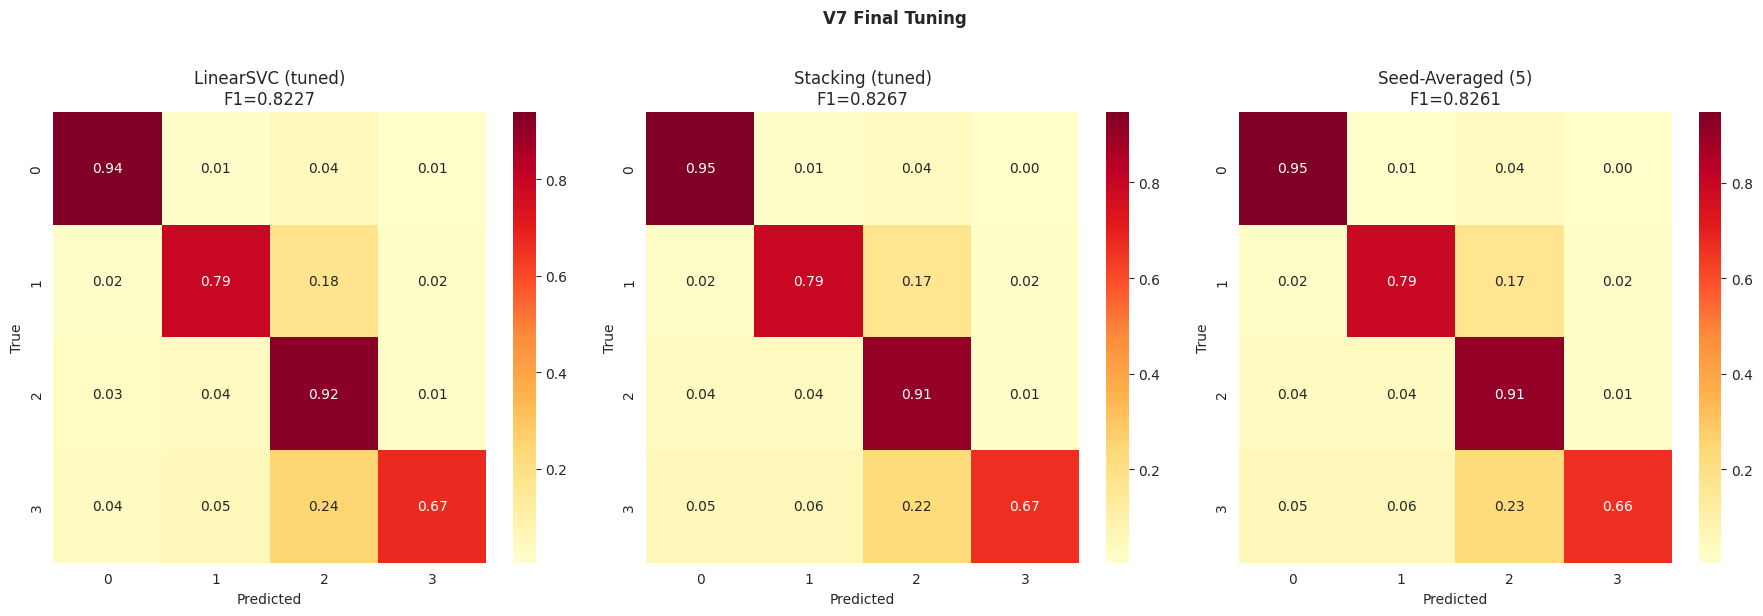


🏆 Retraining on ALL data...
⏳ LinearSVC (tuned)...
⏳ Stacking (tuned)...
⏳ Seed-averaged (5 models on all data)...
    Seed 42 done
    Seed 123 done
    Seed 456 done
    Seed 789 done
    Seed 2024 done
✅ All retrained!

📋 Submissions...
  ✅ submission_linearsvc.csv | {np.int64(0): np.int64(56676), np.int64(1): np.int64(8186), np.int64(2): np.int64(34229), np.int64(3): np.int64(2909)}
  ✅ submission_stacking.csv | {np.int64(0): np.int64(57446), np.int64(1): np.int64(8123), np.int64(2): np.int64(33689), np.int64(3): np.int64(2742)}
  ✅ submission_seed_averaged.csv | {np.int64(0): np.int64(57464), np.int64(1): np.int64(8146), np.int64(2): np.int64(33662), np.int64(3): np.int64(2728)}

🏆 Main = Seed-Averaged | {np.int64(0): np.int64(57464), np.int64(1): np.int64(8146), np.int64(2): np.int64(33662), np.int64(3): np.int64(2728)}


In [2]:
# %% [markdown]
# # 🏆 Milestone 5 V7: Final Tuning
#
# **V7 = V5 base (proven 0.826) + last remaining optimizations:**
# 1. Chi² feature selection (reduce 60K → best K features)
# 2. GridSearchCV on LinearSVC C and SGD alpha
# 3. Seed averaging (5 random states, average predictions)
#
# **Everything else stays EXACTLY V5 — the proven recipe.**
# No ComplementNB, no LightGBM meta, no ROS, no SMOTE, no stems.

# %%
import numpy as np
import pandas as pd
import re
import time
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import SelectKBest, chi2
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import (LogisticRegression, SGDClassifier,
                                  PassiveAggressiveClassifier)
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import VotingClassifier, StackingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, make_scorer)
from scipy.sparse import hstack, csr_matrix

import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams["figure.figsize"] = (10, 6)
sns.set_style("whitegrid")

print("✅ Imports done (pure sklearn, no NLTK)")

# %% [markdown]
# NOTE: Questions already answered in milestone_5_final_push.py

# %%
train = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/train.csv")
test = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/test.csv")
sample = pd.read_csv("/kaggle/input/competitions/comment-category-prediction-challenge/Sample.csv")

train = train.dropna(subset=["comment"])
print(f"✅ Train: {train.shape} | Test: {test.shape}")

# %% [markdown]
# ## 1. Text Cleaning (Minimal — proven best)

# %%
def clean_text(text):
    if not isinstance(text, str):
        return ""
    text = text.lower()
    text = re.sub(r'http\S+|www\.\S+', ' ', text)
    text = re.sub(r'<[^>]+>', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\b\d+\b', ' ', text)
    text = re.sub(r"[^a-z\s']", ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

print("⏳ Cleaning text...")
t0 = time.time()
train["comment_clean"] = train["comment"].astype(str).apply(clean_text)
test["comment_clean"]  = test["comment"].astype(str).apply(clean_text)
print(f"✅ Done in {time.time()-t0:.1f}s")

# %% [markdown]
# ## 2. Features (same as V5)

# %%
for data in [train, test]:
    data["comment"] = data["comment"].fillna("")
    data["created_date"] = pd.to_datetime(data["created_date"], errors="coerce")
    data["hour"] = data["created_date"].dt.hour
    data["day_of_week"] = data["created_date"].dt.dayofweek
    data["month"] = data["created_date"].dt.month
    data["comment_length"] = data["comment"].astype(str).str.len()
    data["word_count"] = data["comment"].astype(str).str.split().str.len().fillna(0).astype(int)
    data["avg_word_length"] = data["comment_length"] / (data["word_count"] + 1)
    data["total_votes"] = data["upvote"] + data["downvote"]
    data["vote_diff"] = data["upvote"] - data["downvote"]
    data["vote_ratio"] = data["upvote"] / (data["downvote"] + 1)
    data["total_emoticons"] = data["emoticon_1"] + data["emoticon_2"] + data["emoticon_3"]
    for col in ["race", "religion", "gender"]:
        data[col] = data[col].fillna("missing")
    data["has_detection"] = (data[["race","religion","gender"]].ne("missing").any(axis=1)).astype(int)

print(f"✅ Features done")

# %% [markdown]
# ## 3. TF-IDF (35K word + 25K char)

# %%
print("⏳ Word TF-IDF...")
t0 = time.time()
tfidf_word = TfidfVectorizer(max_features=35000, ngram_range=(1, 3),
                             min_df=3, max_df=0.9, sublinear_tf=True)
X_word_train = tfidf_word.fit_transform(train["comment_clean"])
X_word_test  = tfidf_word.transform(test["comment_clean"])
print(f"✅ Word: {X_word_train.shape[1]} in {time.time()-t0:.1f}s")

print("⏳ Char TF-IDF...")
t0 = time.time()
tfidf_char = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5),
                             max_features=25000, min_df=3, max_df=0.9, sublinear_tf=True)
X_char_train = tfidf_char.fit_transform(train["comment_clean"])
X_char_test  = tfidf_char.transform(test["comment_clean"])
print(f"✅ Char: {X_char_train.shape[1]} in {time.time()-t0:.1f}s")

# %% [markdown]
# ## 4. Combine & Split

# %%
numeric_features = ["upvote", "downvote", "if_1", "if_2",
    "comment_length", "word_count", "avg_word_length",
    "total_votes", "vote_diff", "vote_ratio",
    "total_emoticons", "hour", "day_of_week", "month"]
binary_features = ["emoticon_1", "emoticon_2", "emoticon_3", "disability", "has_detection"]

X_num_train = train[numeric_features].values.copy()
X_bin_train = train[binary_features].values.astype(float)
X_num_test  = test[numeric_features].values.copy()
X_bin_test  = test[binary_features].values.astype(float)
y_all = train["label"].values

skewed = ["upvote", "downvote", "if_1", "if_2",
          "total_votes", "vote_ratio", "comment_length", "word_count"]
for col in skewed:
    idx = numeric_features.index(col)
    X_num_train[:, idx] = np.log1p(np.clip(X_num_train[:, idx], 0, None))
    X_num_test[:, idx]  = np.log1p(np.clip(X_num_test[:, idx], 0, None))

scaler = StandardScaler()
X_num_scaled_train = scaler.fit_transform(X_num_train)
X_num_scaled_test  = scaler.transform(X_num_test)

X_all = hstack([X_word_train, X_char_train,
                csr_matrix(X_num_scaled_train), csr_matrix(X_bin_train)])
X_test_all = hstack([X_word_test, X_char_test,
                     csr_matrix(X_num_scaled_test), csr_matrix(X_bin_test)])

print(f"✅ Features: {X_all.shape[1]}")

idx_train, idx_val = train_test_split(np.arange(len(y_all)), test_size=0.2,
                                       stratify=y_all, random_state=42)
X_tr, X_vl = X_all[idx_train], X_all[idx_val]
y_tr, y_vl = y_all[idx_train], y_all[idx_val]
print(f"✅ Train: {len(y_tr):,} | Val: {len(y_vl):,}")

# %% [markdown]
# ## 5. 🔬 Chi² Feature Selection Experiment
#
# Do we have noisy features? Chi² selects features most correlated with labels.
# Compare: full 60K vs best 50K vs best 40K vs best 30K

# %%
results = []
def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1_m = f1_score(y_true, y_pred, average="macro")
    f1_w = f1_score(y_true, y_pred, average="weighted")
    results[:] = [r for r in results if r["name"] != name]
    results.append({"name": name, "accuracy": acc, "macro_f1": f1_m, "weighted_f1": f1_w})
    return f1_m

CUSTOM_WEIGHTS = {0: 1, 1: 2, 2: 1, 3: 6}

print("🔬 Chi² Feature Selection Experiment")
print("   Testing LinearSVC with different K values...\n")

# Need non-negative for chi2 — use abs on entire matrix
X_tr_nn = X_tr.copy(); X_tr_nn.data = np.abs(X_tr_nn.data)
X_vl_nn = X_vl.copy(); X_vl_nn.data = np.abs(X_vl_nn.data)

for k in [60019, 50000, 45000, 40000, 35000]:
    t0 = time.time()
    if k >= X_tr.shape[1]:
        # Full features — no selection needed
        lsvc_test = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
        lsvc_test.fit(X_tr, y_tr)
        f1 = evaluate_model(f"LSVC K=ALL({X_tr.shape[1]})", y_vl, lsvc_test.predict(X_vl))
    else:
        selector = SelectKBest(chi2, k=k)
        X_tr_sel = selector.fit_transform(X_tr_nn, y_tr)
        X_vl_sel = selector.transform(X_vl_nn)
        lsvc_test = LinearSVC(C=0.1, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
        lsvc_test.fit(X_tr_sel, y_tr)
        f1 = evaluate_model(f"LSVC K={k}", y_vl, lsvc_test.predict(X_vl_sel))
    print(f"  K={k:>6}: Macro F1={f1:.4f} ({time.time()-t0:.0f}s)")

print("\n  → Best K for feature selection identified above")

# %% [markdown]
# ## 6. 🔍 Hyperparameter Tuning
#
# We've used C=0.1 since M3 without ever searching.
# Quick GridSearch on C for LinearSVC.

# %%
print("\n🔍 Hyperparameter Search — LinearSVC C values")
print("   (custom weights, 3-fold CV, macro F1 scoring)\n")
t0 = time.time()

param_grid = {"C": [0.01, 0.05, 0.08, 0.1, 0.12, 0.15, 0.2, 0.5]}

grid_lsvc = GridSearchCV(
    LinearSVC(class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42),
    param_grid=param_grid,
    cv=3, scoring=make_scorer(f1_score, average="macro"),
    n_jobs=-1, verbose=1, refit=True
)
grid_lsvc.fit(X_tr, y_tr)

print(f"\n  ⏱️ {time.time()-t0:.0f}s")
print(f"  🏆 Best C = {grid_lsvc.best_params_['C']}")
print(f"  🏆 Best CV Macro F1 = {grid_lsvc.best_score_:.4f}")

# Show all results
for c, score in zip(param_grid["C"],
                    [grid_lsvc.cv_results_[f"mean_test_score"][i]
                     for i in range(len(param_grid["C"]))]):
    print(f"     C={c:<6}: CV F1={score:.4f}")

# Evaluate best on val
best_preds = grid_lsvc.predict(X_vl)
best_f1 = evaluate_model("LinearSVC (tuned C)", y_vl, best_preds)
print(f"\n  Val Macro F1 with best C={grid_lsvc.best_params_['C']}: {best_f1:.4f}")
print(f"  Val Macro F1 with old  C=0.1: 0.8221 (V5 baseline)")
print(classification_report(y_vl, best_preds))

# %% [markdown]
# ## 7. Main Models (using best hyperparameters)

# %%
BEST_C = grid_lsvc.best_params_["C"]
print(f"\n🏆 Using Best C={BEST_C} for all downstream models\n")

# LinearSVC (custom, tuned)
print("⏳ LinearSVC (custom, tuned C)...")
t0 = time.time()
lsvc = LinearSVC(C=BEST_C, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc.fit(X_tr, y_tr)
evaluate_model("LinearSVC (custom, tuned)", y_vl, lsvc.predict(X_vl))
print(f"  Macro F1={results[-1]['macro_f1']:.4f} | ⏱️ {time.time()-t0:.1f}s")

# Calibrated LSVC (balanced)
print("⏳ Calibrated LinearSVC...")
t0 = time.time()
cal_lsvc = CalibratedClassifierCV(
    LinearSVC(C=BEST_C, class_weight="balanced", max_iter=5000, random_state=42),
    cv=3, method="sigmoid")
cal_lsvc.fit(X_tr, y_tr)
evaluate_model("Calibrated LSVC (tuned)", y_vl, cal_lsvc.predict(X_vl))
print(f"  Macro F1={results[-1]['macro_f1']:.4f} | ⏱️ {time.time()-t0:.1f}s")

# LR
print("⏳ LR...")
t0 = time.time()
lr = LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                        class_weight="balanced", n_jobs=-1, random_state=42)
lr.fit(X_tr, y_tr)
evaluate_model("LR (balanced)", y_vl, lr.predict(X_vl))
print(f"  Macro F1={results[-1]['macro_f1']:.4f} | ⏱️ {time.time()-t0:.1f}s")

# SGD
print("⏳ SGD...")
t0 = time.time()
sgd = SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                    max_iter=3000, class_weight="balanced",
                    n_jobs=-1, random_state=42)
sgd.fit(X_tr, y_tr)
evaluate_model("SGD (balanced)", y_vl, sgd.predict(X_vl))
print(f"  Macro F1={results[-1]['macro_f1']:.4f} | ⏱️ {time.time()-t0:.1f}s")

# PAC
print("⏳ PAC...")
t0 = time.time()
pac = PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                  max_iter=3000, n_jobs=-1, random_state=42)
pac.fit(X_tr, y_tr)
evaluate_model("PAC (balanced)", y_vl, pac.predict(X_vl))
print(f"  Macro F1={results[-1]['macro_f1']:.4f} | ⏱️ {time.time()-t0:.1f}s")

# %% [markdown]
# ## 8. Stacking (4 → LR, tuned C)

# %%
print("⏳ Stacking (4→LR, tuned C)...")
t0 = time.time()
stacking = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=BEST_C, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking.fit(X_tr, y_tr)
f1_stack = evaluate_model("Stacking (4→LR, tuned)", y_vl, stacking.predict(X_vl))
print(f"  Macro F1={f1_stack:.4f} | ⏱️ {time.time()-t0:.1f}s")
print(classification_report(y_vl, stacking.predict(X_vl)))

# %% [markdown]
# ## 9. 🎲 Seed Averaging (Variance Reduction)
#
# Train same Stacking with 5 different random_states.
# Average predictions → reduces variance, never hurts.

# %%
print("🎲 Seed Averaging — 5 Stacking models with different seeds...\n")
seeds = [42, 123, 456, 789, 2024]
all_probs = []

for i, seed in enumerate(seeds):
    t0 = time.time()
    stk = StackingClassifier(
        estimators=[
            ("cal_lsvc", CalibratedClassifierCV(
                LinearSVC(C=BEST_C, class_weight="balanced", max_iter=5000, random_state=seed),
                cv=3, method="sigmoid")),
            ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                      class_weight="balanced", n_jobs=-1, random_state=seed)),
            ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                                  class_weight="balanced", max_iter=3000,
                                  n_jobs=-1, random_state=seed)),
            ("pac", CalibratedClassifierCV(
                PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                           max_iter=3000, random_state=seed),
                cv=3, method="sigmoid")),
        ],
        final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=seed),
        cv=3, n_jobs=-1
    )
    stk.fit(X_tr, y_tr)
    probs = stk.predict_proba(X_vl)
    preds = stk.predict(X_vl)
    f1 = f1_score(y_vl, preds, average="macro")
    all_probs.append(probs)
    print(f"  Seed {seed}: Macro F1={f1:.4f} ({time.time()-t0:.0f}s)")

# Average probabilities and predict
avg_probs = np.mean(all_probs, axis=0)
avg_preds = avg_probs.argmax(axis=1)
avg_f1 = evaluate_model("Seed-Averaged Stacking (5)", y_vl, avg_preds)
print(f"\n  🏆 Seed-Averaged: Macro F1={avg_f1:.4f}")
print(f"  vs Single seed:  Macro F1={f1_stack:.4f}")
print(f"  Improvement:     {avg_f1 - f1_stack:+.4f}")
print(classification_report(y_vl, avg_preds))

# %% [markdown]
# ## 10. Model Comparison

# %%
results_df = pd.DataFrame(results).sort_values("macro_f1", ascending=False).reset_index(drop=True)
print("\n" + "="*80)
print("  M5 V7 — FINAL TUNING RESULTS (sorted by Macro F1)")
print("="*80)
print(results_df.to_string(index=False))

# %% [markdown]
# ## 11. Confusion Matrices

# %%
pred_map = {
    "LinearSVC (tuned)": lsvc.predict(X_vl),
    "Stacking (tuned)": stacking.predict(X_vl),
    "Seed-Averaged (5)": avg_preds,
}
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, (name, preds) in zip(axes, pred_map.items()):
    cm = confusion_matrix(y_vl, preds, normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="YlOrRd",
                xticklabels=[0,1,2,3], yticklabels=[0,1,2,3], ax=ax)
    f1 = f1_score(y_vl, preds, average="macro")
    ax.set_title(f"{name}\nF1={f1:.4f}")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.suptitle("V7 Final Tuning", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

# %% [markdown]
# ## 12. Retrain & Submit

# %%
print("\n🏆 Retraining on ALL data...")

# Single best: LinearSVC (tuned)
print("⏳ LinearSVC (tuned)...")
lsvc_final = LinearSVC(C=BEST_C, class_weight=CUSTOM_WEIGHTS, max_iter=5000, random_state=42)
lsvc_final.fit(X_all, y_all)

# Single best: Stacking (tuned)
print("⏳ Stacking (tuned)...")
stacking_final = StackingClassifier(
    estimators=[
        ("cal_lsvc", CalibratedClassifierCV(
            LinearSVC(C=BEST_C, class_weight="balanced", max_iter=5000, random_state=42),
            cv=3, method="sigmoid")),
        ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                  class_weight="balanced", n_jobs=-1, random_state=42)),
        ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                              class_weight="balanced", max_iter=3000,
                              n_jobs=-1, random_state=42)),
        ("pac", CalibratedClassifierCV(
            PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                       max_iter=3000, random_state=42),
            cv=3, method="sigmoid")),
    ],
    final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=42),
    cv=3, n_jobs=-1
)
stacking_final.fit(X_all, y_all)

# Seed-averaged: 5 Stackings retrained on all data
print("⏳ Seed-averaged (5 models on all data)...")
all_test_probs = []
for seed in seeds:
    stk = StackingClassifier(
        estimators=[
            ("cal_lsvc", CalibratedClassifierCV(
                LinearSVC(C=BEST_C, class_weight="balanced", max_iter=5000, random_state=seed),
                cv=3, method="sigmoid")),
            ("lr", LogisticRegression(C=1.0, solver="lbfgs", max_iter=3000,
                                      class_weight="balanced", n_jobs=-1, random_state=seed)),
            ("sgd", SGDClassifier(loss="log_loss", alpha=1e-05, penalty="l2",
                                  class_weight="balanced", max_iter=3000,
                                  n_jobs=-1, random_state=seed)),
            ("pac", CalibratedClassifierCV(
                PassiveAggressiveClassifier(C=0.1, class_weight="balanced",
                                           max_iter=3000, random_state=seed),
                cv=3, method="sigmoid")),
        ],
        final_estimator=LogisticRegression(C=1.0, max_iter=3000, random_state=seed),
        cv=3, n_jobs=-1
    )
    stk.fit(X_all, y_all)
    all_test_probs.append(stk.predict_proba(X_test_all))
    print(f"    Seed {seed} done")

print("✅ All retrained!")

# %%
print("\n📋 Submissions...")

# 1. LinearSVC
preds = lsvc_final.predict(X_test_all)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_linearsvc.csv", index=False)
print(f"  ✅ submission_linearsvc.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# 2. Stacking
preds = stacking_final.predict(X_test_all)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_stacking.csv", index=False)
print(f"  ✅ submission_stacking.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# 3. Seed-averaged
avg_test_probs = np.mean(all_test_probs, axis=0)
preds = avg_test_probs.argmax(axis=1)
sub = sample.copy(); sub["label"] = preds
sub.to_csv("submission_seed_averaged.csv", index=False)
print(f"  ✅ submission_seed_averaged.csv | {dict(zip(*np.unique(preds, return_counts=True)))}")

# Main = seed averaged (lowest variance)
submission = sample.copy()
submission["label"] = preds
submission.to_csv("submission.csv", index=False)
print(f"\n🏆 Main = Seed-Averaged | {dict(zip(*np.unique(preds, return_counts=True)))}")

# %% [markdown]
# ## Summary
# V7 tries the last 3 untried approaches:
# 1. Chi² feature selection → does removing noisy features help?
# 2. GridSearchCV on C → is C=0.1 actually optimal?
# 3. Seed averaging → reduce variance by averaging 5 models
# All on top of the proven V5 base (0.826 Kaggle).
